![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Sesión 2 · Versión resuelta · referencia</div><div style="font-size:22px;font-weight:700;margin-top:4px">L2.2 · Reducción de dimensionalidad y detección de anomalías</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Objetivo** | Comprimir datos de muchas variables sin perder lo esencial (**PCA**), visualizarlos en 2D (**t-SNE**) y encontrar lo que no encaja (**anomalías**) con Isolation Forest y LOF. |
| **Duración** | ≈ 75 min |
| **Teoría** | Manual M2 §8–§9 · Animaciones A2.5 a A2.8 |
| **Datos icónicos** | **dígitos** de scikit-learn (8 × 8) y nubes 2D con valores atípicos |
| **Escala realista (reto)** | **MNIST** (784 variables) y **Fashion-MNIST**: detectar prendas «extrañas» entrenando solo con camisetas |

**Partes:** 1 · PCA: varianza explicada y reconstrucción → 2 · t-SNE: mapas para mirar, no para medir → 3 · anomalías: Isolation Forest y LOF → reto: detector de novedades en Fashion-MNIST.

## 0 · Configuración

In [1]:
import gzip
import os
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 2026
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
COLORES = ["#004890", "#C2410C", "#A87900", "#3A7D44", "#6B4C9A", "#1B8A8F", "#B23A48", "#5C6B73", "#D08C2E", "#2F5D8A"]
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=COLORES), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
CACHE = os.path.expanduser("~/.cache/ml-unibe")
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"


def descargar(nombre):
    """Descarga un archivo del repositorio público de datasets de Keras (una sola vez)."""
    os.makedirs(CACHE, exist_ok=True)
    ruta = os.path.join(CACHE, nombre)
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(URL + nombre, ruta)
    return ruta


def mapa_digitos(ax, Z, y, titulo):
    """Dispersión 2D coloreada por dígito, con el número escrito en el centro de cada grupo."""
    for k in range(10):
        m = y == k
        ax.scatter(Z[m, 0], Z[m, 1], s=6, color=COLORES[k], alpha=0.7)
        cx, cy = np.median(Z[m], axis=0)
        ax.text(cx, cy, str(k), fontsize=13, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=COLORES[k]))
    ax.set_title(titulo, fontsize=10); ax.set_xticks([]); ax.set_yticks([])


print(f"scikit-learn {sklearn.__version__} · semilla {SEED}")

scikit-learn 1.9.1 · semilla 2026


## Parte 1 · PCA: varianza explicada y reconstrucción

El **análisis de componentes principales** (Pearson, 1901; Hotelling, 1933) busca nuevas direcciones, combinaciones lineales de las variables originales, ordenadas por cuánta **varianza** capturan (A2.5). Si las primeras pocas explican casi todo, podemos quedarnos solo con ellas.

Empezamos con los dígitos de 8 × 8: 64 variables.

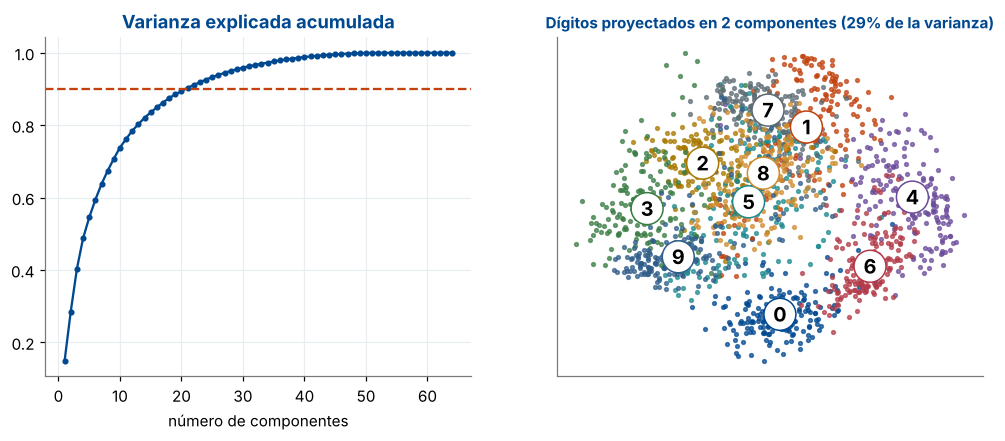

In [2]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

dig = load_digits()
X_d, y_d = dig.data, dig.target
pca_d = PCA().fit(X_d)
acum = np.cumsum(pca_d.explained_variance_ratio_)
Z2 = PCA(n_components=2).fit_transform(X_d)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(range(1, 65), acum, "o-", ms=3); axs[0].axhline(0.9, color=UNIBE["naranja"], ls="--")
axs[0].set_title("Varianza explicada acumulada"); axs[0].set_xlabel("número de componentes")
mapa_digitos(axs[1], Z2, y_d, f"Dígitos proyectados en 2 componentes ({acum[1]:.0%} de la varianza)")
plt.show()

**Tu turno.** ¿Cuántas componentes hacen falta para conservar el 90 % y el 95 % de la varianza? Pista: `np.argmax(acum >= 0.9) + 1`.

In [3]:
# TODO: calcula k90 y k95.
k90 = int(np.argmax(acum >= 0.90)) + 1
k95 = int(np.argmax(acum >= 0.95)) + 1
print(f"90 % de la varianza con {k90} de 64 componentes · 95 % con {k95}")
assert 15 <= k90 <= 25

90 % de la varianza con 21 de 64 componentes · 95 % con 29


### Escala realista: comprimir MNIST

En MNIST cada imagen tiene 784 píxeles. Proyectamos en k componentes y **reconstruimos** con `inverse_transform`: si la imagen se reconoce, esas k componentes guardaban lo esencial.

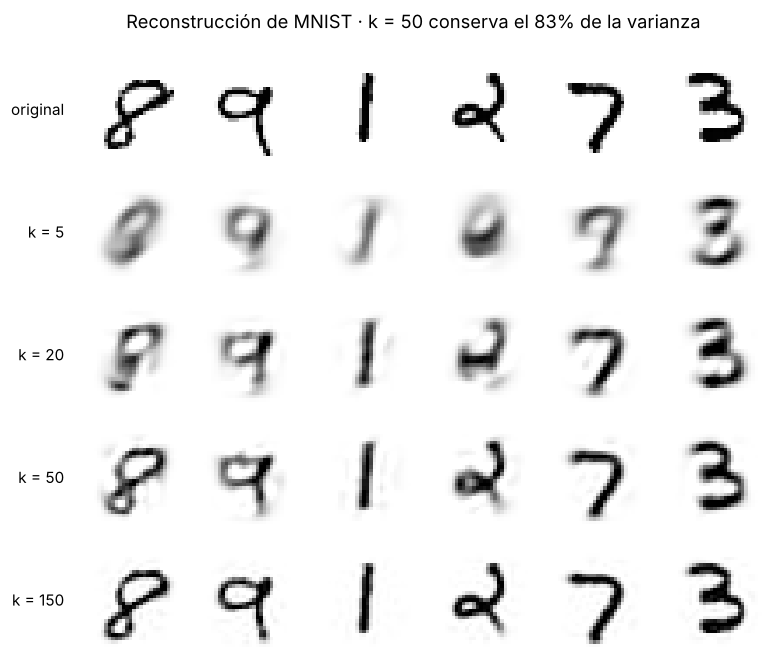

In [4]:
d = np.load(descargar("mnist.npz"))
idx = np.random.default_rng(SEED).choice(len(d["x_train"]), 10_000, replace=False)
X_mn, y_mn = d["x_train"][idx].reshape(-1, 784) / 255.0, d["y_train"][idx]
pca_mn = PCA(n_components=200, random_state=SEED).fit(X_mn)
ks, muestra = [5, 20, 50, 150], [0, 1, 2, 3, 4, 7]
fig, axs = plt.subplots(len(ks) + 1, len(muestra), figsize=(8, 7))
for j, i in enumerate(muestra):
    axs[0, j].imshow(X_mn[i].reshape(28, 28), cmap="Greys"); axs[0, j].axis("off")
    for r, k in enumerate(ks, start=1):
        z = pca_mn.transform(X_mn[i:i + 1])[:, :k]
        rec = z @ pca_mn.components_[:k] + pca_mn.mean_
        axs[r, j].imshow(rec.reshape(28, 28).clip(0, 1), cmap="Greys", vmin=0, vmax=1); axs[r, j].axis("off")
for r, k in enumerate(["original"] + [f"k = {k}" for k in ks]):
    axs[r, 0].text(-6, 14, k, ha="right", va="center", fontsize=10)
var = np.cumsum(pca_mn.explained_variance_ratio_)
plt.suptitle(f"Reconstrucción de MNIST · k = 50 conserva el {var[49]:.0%} de la varianza", y=0.94); plt.show()

Con 50 componentes (el 6 % de las 784 variables) los dígitos ya se leen. Esto sirve para **acelerar** otros modelos, **quitar ruido** y **guardar** menos datos. El precio: las componentes son mezclas de píxeles y no tienen un significado tan directo como «la edad» o «el ingreso».

## Parte 2 · t-SNE: mapas para mirar, no para medir

PCA es **lineal**: en 2D los dígitos se solapan. **t-SNE** (van der Maaten y Hinton, 2008) es no lineal: intenta que los puntos que eran **vecinos** en 64 dimensiones sigan siéndolo en 2D (A2.6). Es excelente para explorar, pero:

- las **distancias entre grupos** y los **tamaños** de los grupos del mapa no significan nada;
- el resultado depende de la **perplejidad** (≈ cuántos vecinos considera) y de la semilla;
- no sirve para transformar datos nuevos (no tiene `transform`).

**Tu turno.** Calcula t-SNE de los dígitos con perplejidad 30 y compáralo con PCA.

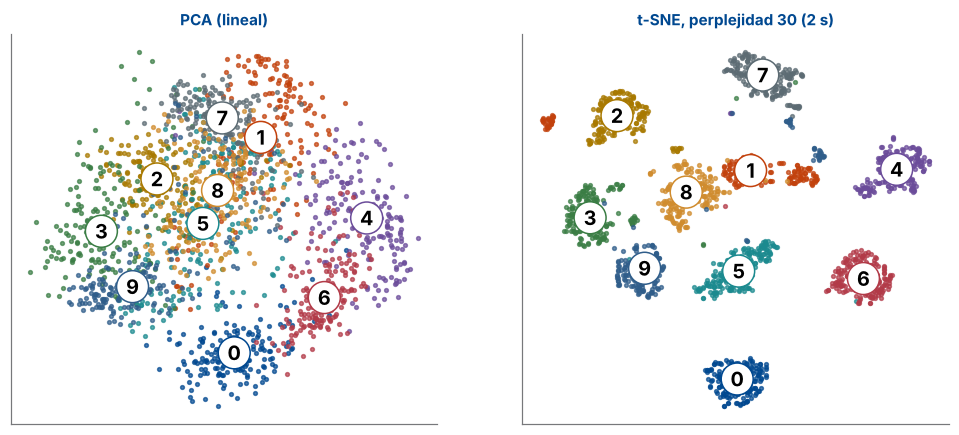

In [5]:
from sklearn.manifold import TSNE

# TODO: Z_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(X_d)
t0 = time.perf_counter()
Z_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(X_d)
seg = time.perf_counter() - t0
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
mapa_digitos(axs[0], Z2, y_d, "PCA (lineal)")
mapa_digitos(axs[1], Z_tsne, y_d, f"t-SNE, perplejidad 30 ({seg:.0f} s)")
plt.show()

**Experimento.** La perplejidad cambia el mapa. ¿Cuál es el «verdadero»?

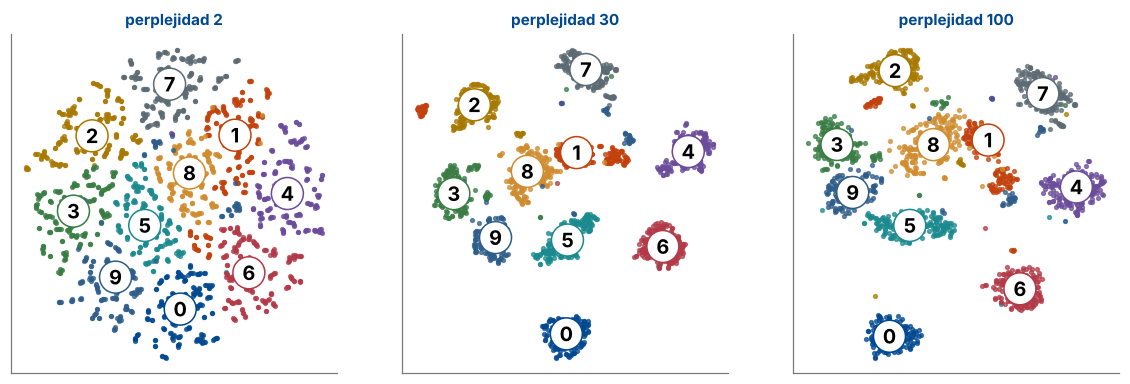

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, p in zip(axs, [2, 30, 100]):
    Z = Z_tsne if p == 30 else TSNE(n_components=2, perplexity=p, random_state=SEED).fit_transform(X_d)
    mapa_digitos(ax, Z, y_d, f"perplejidad {p}")
plt.show()

Con perplejidad 2, t-SNE solo atiende a los vecinos inmediatos: los grupos se deshacen en grumos y se tocan. Con 30 y con 100 los grupos se ven compactos, pero en posiciones y tamaños distintos. Ninguno es el verdadero: por eso las distancias entre grupos de un t-SNE no se interpretan.

Hoy también se usa **UMAP** (McInnes y colaboradores, 2018), más rápido y con `transform`; no viene en scikit-learn (paquete `umap-learn`).

## Parte 3 · Anomalías: Isolation Forest y LOF

Una **anomalía** es un dato que no se parece a los demás: un fraude, un sensor dañado, un error de captura. Dos ideas clásicas:

- **Isolation Forest** (Liu, Ting y Zhou, 2008; A2.7): árboles con cortes **al azar**. Un punto raro queda aislado en pocos cortes; su camino promedio es corto.
- **LOF**, *Local Outlier Factor* (Breunig y colaboradores, 2000; A2.8): compara la densidad alrededor de un punto con la de sus vecinos. Detecta puntos raros **localmente**, aunque estén cerca de un grupo grande y disperso.

Los probamos en un ejemplo icónico: un grupo denso, uno disperso y 12 puntos sueltos.

In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

rng = np.random.default_rng(SEED)
denso = rng.normal([0, 0], 0.3, size=(150, 2))
disperso = rng.normal([4, 3], 1.2, size=(150, 2))
sueltos = np.array([[1.3, 1.2], [-1.3, 1.0], [1.2, -1.3], [-1.2, -1.2],  # cerca del grupo denso
                    [8.5, 7], [-3, 6], [8, -2], [-3.5, -3], [2, 8], [7.5, 8.5], [-4, 2], [9, 1]])
X_o = np.vstack([denso, disperso, sueltos])
es_anom = np.r_[np.zeros(300), np.ones(12)].astype(bool)

**Tu turno.** Entrena `IsolationForest(contamination=12/312)` y `LocalOutlierFactor(n_neighbors=20, contamination=12/312)`. Ambos devuelven −1 para las anomalías y 1 para lo normal con `fit_predict`. ¿Cuántas de las 12 anomalías verdaderas encuentra cada uno?

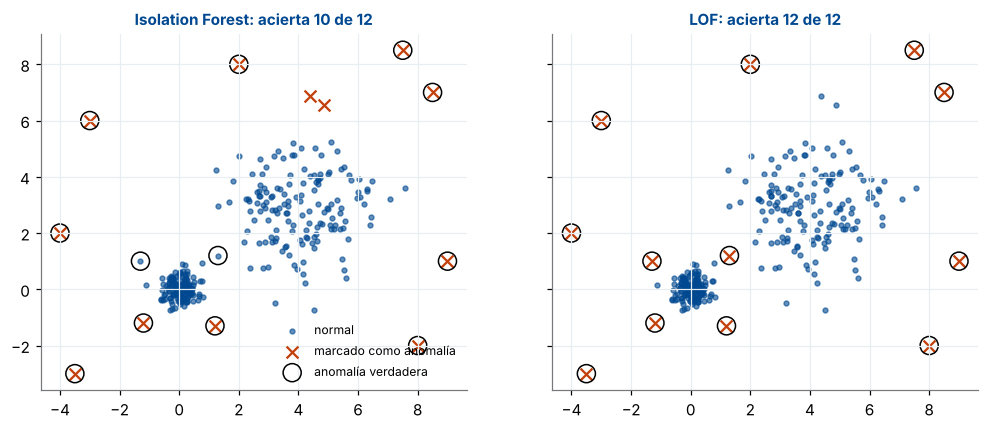

Los 4 sueltos junto al grupo denso → Isolation Forest: 2 de 4 · LOF: 4 de 4


In [8]:
# TODO: pred_iso y pred_lof (arreglos booleanos: True = anomalía).
pred_iso = IsolationForest(contamination=12 / 312, random_state=SEED).fit_predict(X_o) == -1
pred_lof = LocalOutlierFactor(n_neighbors=20, contamination=12 / 312).fit_predict(X_o) == -1
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, pred, nombre in [(axs[0], pred_iso, "Isolation Forest"), (axs[1], pred_lof, "LOF")]:
    ax.scatter(X_o[~pred, 0], X_o[~pred, 1], s=10, color=UNIBE["azul"], alpha=0.6, label="normal")
    ax.scatter(X_o[pred, 0], X_o[pred, 1], s=60, color=UNIBE["naranja"], marker="x", label="marcado como anomalía")
    ax.scatter(X_o[es_anom, 0], X_o[es_anom, 1], s=140, facecolors="none", edgecolors="black", label="anomalía verdadera")
    ax.set_title(f"{nombre}: acierta {int(np.sum(pred & es_anom))} de 12", fontsize=10)
axs[0].legend(loc="lower right", fontsize=8); plt.show()
cerca = slice(300, 304)
print("Los 4 sueltos junto al grupo denso → Isolation Forest:", int(pred_iso[cerca].sum()), "de 4 · LOF:", int(pred_lof[cerca].sum()), "de 4")

Los cuatro puntos junto al grupo denso están a la misma distancia que muchos puntos normales del grupo disperso. Isolation Forest mira el conjunto **globalmente** y tiende a confundirlos con los del borde del grupo disperso; LOF compara cada punto con **su vecindario** y los reconoce como raros. Ninguno es mejor siempre: depende de si lo raro es global o local.

**Preguntas para la discusión:**

1. Un hospital tiene 300 variables por paciente. ¿Usarías PCA antes de agrupar pacientes? ¿Qué pierdes?
2. Un colega muestra un mapa t-SNE y dice: «el grupo A está muy lejos del B, así que son muy distintos». ¿Qué le respondes?
3. ¿Por qué `contamination` es una decisión de negocio y no un detalle técnico?

> **Respuesta de referencia**

1. Sí, suele ayudar: las distancias en 300 dimensiones tienen mucho ruido y PCA concentra la señal y acelera. Se pierde interpretabilidad (cada componente mezcla variables) y la varianza no siempre es lo importante: una variable con poca varianza puede ser clínicamente decisiva. Hay que escalar antes y revisar las cargas de las componentes.
2. Que en t-SNE las distancias entre grupos y sus tamaños no se conservan; solo los vecindarios locales. Para afirmar que A y B son distintos hay que medirlo en el espacio original (o con PCA, que sí conserva distancias de forma lineal).
3. Porque fija cuántos casos se marcan: cada alerta cuesta revisión humana, y cada anomalía no detectada cuesta un fraude o una falla. El umbral se elige con los costos de cada error (como el umbral de clasificación de la sesión 1), no por defecto.

## Reto · Escala realista: un detector de novedades en Fashion-MNIST

Imagina una fábrica de **camisetas** con una cámara al final de la línea. Solo tenemos fotos de camisetas buenas; queremos una alarma cuando pase **cualquier otra cosa**. Entrenamos solo con 3 000 camisetas (detección de **novedades**) y probamos con 500 camisetas y 500 imágenes de otras prendas.

Comparamos tres puntajes de rareza:

- **error de reconstrucción de PCA** con 30 componentes: lo que el modelo de camisetas no sabe reconstruir;
- **Isolation Forest**;
- **LOF** con `novelty=True`, que permite puntuar datos nuevos.

La métrica es el **AUC ROC** de la sesión 1: 1 = separa perfecto, 0,5 = al azar.

In [9]:
from sklearn.metrics import roc_auc_score


def cargar_fashion():
    """Fashion-MNIST desde el repositorio público de Keras (formato IDX comprimido)."""
    def imagenes(nombre):
        with gzip.open(descargar(nombre)) as f:
            return np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784) / 255.0

    def etiquetas(nombre):
        with gzip.open(descargar(nombre)) as f:
            return np.frombuffer(f.read(), np.uint8, offset=8)
    return (imagenes("train-images-idx3-ubyte.gz"), etiquetas("train-labels-idx1-ubyte.gz"),
            imagenes("t10k-images-idx3-ubyte.gz"), etiquetas("t10k-labels-idx1-ubyte.gz"))


PRENDAS = ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "zapatilla", "bolso", "botín"]
Ftr, fytr, Fte, fyte = cargar_fashion()
normal_tr = Ftr[fytr == 0][:3000]
rng = np.random.default_rng(SEED)
otros = rng.choice(np.flatnonzero(fyte != 0), 500, replace=False)
X_nov = np.vstack([Fte[fyte == 0][:500], Fte[otros]])
y_nov = np.r_[np.zeros(500), np.ones(500)]                 # 1 = novedad (no es camiseta)
prenda_nov = np.r_[np.zeros(500, int), fyte[otros]]

In [10]:
# TODO (reto): calcula los tres puntajes de rareza (más alto = más raro) y su AUC.
#   PCA: error cuadrático de reconstrucción · Isolation Forest y LOF(novelty=True): -score_samples
pca_f = PCA(n_components=30, random_state=SEED).fit(normal_tr)
s_pca = ((X_nov - pca_f.inverse_transform(pca_f.transform(X_nov))) ** 2).sum(axis=1)
s_iso = -IsolationForest(n_estimators=200, random_state=SEED).fit(normal_tr).score_samples(X_nov)
s_lof = -LocalOutlierFactor(n_neighbors=20, novelty=True).fit(normal_tr).score_samples(X_nov)
for nombre, s in [("Error de reconstrucción PCA", s_pca), ("Isolation Forest", s_iso), ("LOF (novelty)", s_lof)]:
    print(f"{nombre:<28} AUC = {roc_auc_score(y_nov, s):.3f}")

Error de reconstrucción PCA  AUC = 0.900
Isolation Forest             AUC = 0.905
LOF (novelty)                AUC = 0.854


¿Qué prendas engañan al detector? Calculamos, por prenda, qué fracción supera el umbral que deja pasar el 95 % de las camisetas buenas.

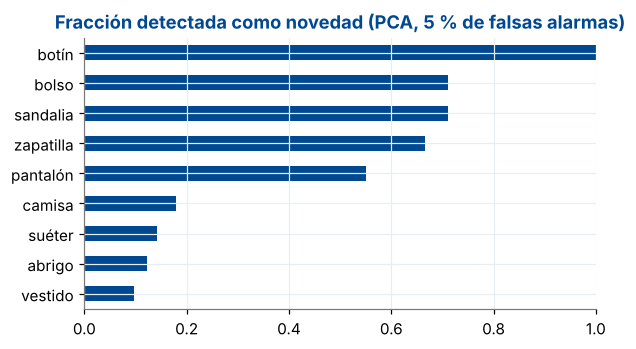

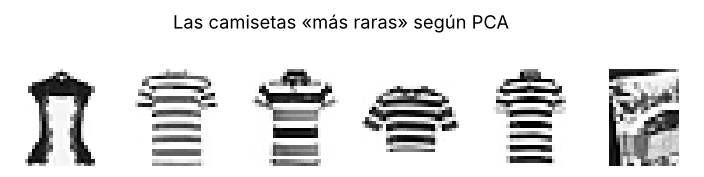

In [11]:
umbral = np.quantile(s_pca[:500], 0.95)
tasa = {PRENDAS[k]: float(np.mean(s_pca[prenda_nov == k] > umbral)) for k in range(1, 10)}
pd.Series(tasa).sort_values().plot.barh(figsize=(6, 3.2), color=UNIBE["azul"])
plt.title("Fracción detectada como novedad (PCA, 5 % de falsas alarmas)"); plt.xlim(0, 1); plt.show()
peores = np.argsort(s_pca[:500])[-6:]
fig, axs = plt.subplots(1, 6, figsize=(8, 1.6))
for ax, i in zip(axs, peores):
    ax.imshow(X_nov[i].reshape(28, 28), cmap="Greys"); ax.axis("off")
plt.suptitle("Las camisetas «más raras» según PCA", y=1.1); plt.show()

Los botines se detectan siempre, y bolsos, sandalias y zapatillas en la mayoría de los casos. En cambio, **vestidos, abrigos, suéteres y camisas** se parecen tanto a una camiseta que casi todos pasan, y también pasa cerca de la mitad de los pantalones, algo que ninguna persona confundiría: lo raro para el modelo no es lo mismo que lo raro para nosotros. Y las camisetas más raras suelen ser estampadas o fotografiadas de forma distinta: el detector aprende «lo típico», no «lo correcto». En un sistema real, esas alarmas las revisa una persona y el umbral se ajusta con los costos de cada error.

## Desafío opcional con IA agéntica · Un detector de anomalías revisado por ti

**Objetivo.** Pedirle a un asistente que construya un detector de novedades con otra clase de Fashion-MNIST y comprobar que no use las etiquetas de las anomalías para ajustarlo.

**Prompt inicial.** Úsalo en la herramienta que prefieras (Claude Code, Codex, Gemini en Colab, ChatGPT…), con este notebook resuelto como contexto. Pide primero un plan y revisa cada paso antes de aprobarlo.

```text
Tengo el notebook resuelto L2.2 (PCA, t-SNE, Isolation Forest y LOF; reto: detector de novedades en Fashion-MNIST entrenado solo con camisetas). Muéstrame primero un plan y espera mi aprobación. Luego repite el reto tomando como clase normal las zapatillas (clase 7): entrena solo con zapatillas, compara el error de reconstrucción de PCA con 10, 30 y 60 componentes, Isolation Forest y LOF con novelty=True, y reporta el AUC ROC en un conjunto de prueba con 500 zapatillas y 500 imágenes de otras clases. Muestra las 8 imágenes de otras clases que el mejor detector considera más normales y explica por qué lo engañan.
```

**Cómo verificar el resultado**

- El detector se entrena solo con zapatillas; las otras clases solo aparecen en la prueba.
- El número de componentes no se elige mirando el AUC de la misma prueba que se reporta (o se declara como limitación).
- La explicación de los errores se apoya en las imágenes mostradas (por ejemplo, sandalias o botines parecidos).

**Declara el uso de IA** (como pide el sílabo): herramienta, prompts relevantes, qué verificaste tú y qué corregiste. El desafío es opcional y no se califica; lo que cuenta es que puedas explicar cada decisión.